In [4]:
# imports
from pathlib import Path
import sys
from scipy.stats import gaussian_kde
import numpy as np

# Garante que a raiz do projeto esteja disponível para importação
raiz_projeto = Path.cwd().parent
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

from catalogo_variaveis import selecionar_grupos
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import catalogo_variaveis

# Carga dos dados

In [8]:
df = pd.read_csv("../data/processed/dataset_soja.csv")

In [ ]:
df.shape

,localidade,ano,producao,rendimento,area_colhida,area_plantada,produto,cod_ibge,razao_colhida_plantada,perda_flag,...,argila,silte,prof_max_cm,n_perfis,lat,lon,solo_imputado,solo_dist_km,cad_mm,lag1_rel
0,Aguaí - SP,2000,2400.0,1500.0,1600.0,1600.0,soja,3500303,1.0,0,...,449.000000,113.666667,88.0,NaN,-22.0500,-47.0403,1,29.899939,96.412800,NaN
1,Altair - SP,2000,576.0,1920.0,300.0,300.0,soja,3500907,1.0,0,...,240.500000,27.833333,140.0,NaN,-20.5333,-49.0939,1,43.883724,82.580000,NaN
2,Altinópolis - SP,2000,3360.0,2100.0,1600.0,1600.0,soja,3501004,1.0,0,...,292.000000,54.000000,52.5,4.0,-21.0180,-47.3862,0,0.000000,47.166000,NaN
3,Analândia - SP,2000,360.0,1800.0,200.0,200.0,soja,3502002,1.0,0,...,340.000000,300.000000,78.5,32.0,-22.1211,-47.6780,0,0.000000,96.712000,NaN
4,Andradina - SP,2000,90.0,1800.0,50.0,50.0,soja,3502101,1.0,0,...,117.333333,14.166667,65.0,NaN,-20.8356,-51.3297,1,66.811664,46.206333,NaN


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8934 entries, 0 to 8933
Data columns (total 67 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   localidade              8934 non-null   str    
 1   ano                     8934 non-null   int64  
 2   producao                8934 non-null   float64
 3   rendimento              8934 non-null   float64
 4   area_colhida            8934 non-null   float64
 5   area_plantada           8934 non-null   float64
 6   produto                 8934 non-null   str    
 7   cod_ibge                8934 non-null   int64  
 8   razao_colhida_plantada  8934 non-null   float64
 9   perda_flag              8934 non-null   int64  
 10  rendimento_calc         8934 non-null   float64
 11  rend_repetido           8934 non-null   int64  
 12  y_log                   8934 non-null   float64
 13  peso                    8934 non-null   float64
 14  implant_prec            8934 non-null   float64
 15

In [9]:
df.describe()

,ano,producao,rendimento,area_colhida,area_plantada,cod_ibge,razao_colhida_plantada,perda_flag,rendimento_calc,rend_repetido,...,argila,silte,prof_max_cm,n_perfis,lat,lon,solo_imputado,solo_dist_km,cad_mm,lag1_rel
count,8934.000000,8934.000000,8934.000000,8934.000000,8934.000000,8.934000e+03,8934.000000,8934.000000,8934.000000,8934.000000,...,7982.000000,7982.000000,7982.000000,1495.000000,8934.000000,8934.000000,8934.000000,8934.000000,8934.000000,7961.000000
mean,2014.072644,7169.701589,2790.053280,2364.676964,2371.532796,3.528799e+06,0.998335,0.003358,2790.079215,0.451198,...,326.208991,82.520337,106.687108,11.931773,-21.813639,-49.105067,0.832662,43.997624,84.057934,-0.009560
std,7.566059,19141.760281,661.586181,5688.968984,5704.916056,1.654537e+04,0.029653,0.057854,661.574681,0.497640,...,156.003265,51.923071,42.486322,39.129766,1.068733,1.393255,0.373298,28.150562,19.953006,0.213604
min,2000.000000,15.000000,800.000000,10.000000,10.000000,3.500105e+06,0.150000,0.000000,800.000000,0.000000,...,18.000000,2.000000,20.000000,2.000000,-24.772000,-52.836900,0.000000,0.000000,18.090000,-1.203973
25%,2007.000000,463.250000,2400.000000,200.000000,200.000000,3.514957e+06,1.000000,0.000000,2400.000000,0.000000,...,215.500000,45.166667,75.833333,4.000000,-22.651600,-50.200200,1.000000,24.702710,75.020000,-0.117783
50%,2015.000000,1484.500000,2719.500000,540.000000,544.000000,3.529203e+06,1.000000,0.000000,2719.641816,0.000000,...,317.333333,73.500000,101.666667,6.000000,-21.735850,-49.142500,1.000000,46.058412,82.358222,0.000000
75%,2021.000000,5400.000000,3194.500000,1955.000000,1967.500000,3.543204e+06,1.000000,0.000000,3194.871795,1.000000,...,438.333333,114.000000,137.500000,8.000000,-20.940500,-47.938500,1.000000,63.215307,96.366667,0.130736
max,2025.000000,360000.000000,5400.000000,82000.000000,82000.000000,3.557303e+06,1.000000,1.000000,5400.000000,1.000000,...,762.500000,321.000000,450.000000,310.000000,-19.907300,-45.060000,1.000000,116.777435,137.200000,0.765654


In [10]:
df.describe(include="object")

C:\Users\Samsung\AppData\Local\Temp\ipykernel_19772\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,localidade,produto
count,8934,8934
unique,521,1
top,Aguaí - SP,soja
freq,26,8934


# Análise das variáveis numéricas

In [2]:
columns_to_plot = [
    "ano",
    "producao",
    "rendimento",
    "area_colhida",
    "area_plantada",
    "peso",
]

columns_to_plot_implant = [
    "implant_prec",
    "implant_tmax",
    "implant_tmin",
    "implant_rad",
    "implant_defic",
    "implant_estresse",
    "implant_dias_calor",
    "implant_dias_geada",
    "implant_seca_max",
    "implant_gd",
    "implant_umsolo",
]

In [ ]:
def plot_histograms_kde(df, columns, bins=30, ncols=2):
    nrows = math.ceil(len(columns) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False
    )
    axes = axes.flatten()

    for ax, col in zip(axes, columns):
        data = df[col].dropna()

        if data.empty:
            ax.set_title(f"Sem dados: {col}")
            continue

        q1 = data.quantile(0.25)
        q3 = data.quantile(0.75)
        iqr = q3 - q1
        limite_superior = q3 + 3.5 * iqr

        x_min = data.min()
        data_filtrada = data[data <= limite_superior]
        bins_range = np.linspace(x_min, limite_superior, bins + 1)

        ax.hist(
            data_filtrada,
            bins=bins_range,
            density=True,
            color="skyblue",
            edgecolor="black",
            alpha=0.6,
            label="Histograma",
        )

        if len(data_filtrada) > 1 and data_filtrada.nunique() > 1:
            kde = gaussian_kde(data_filtrada)
            x = np.linspace(x_min, limite_superior, 300)
            ax.plot(x, kde(x), color="red", linewidth=2, label="KDE")

        media = data_filtrada.mean()
        mediana = data_filtrada.median()

        ax.axvline(
            media,
            color="blue",
            linestyle="--",
            linewidth=2,
            label=f"Média: {media:.2f}",
        )
        ax.axvline(
            mediana,
            color="green",
            linestyle="-.",
            linewidth=2,
            label=f"Mediana: {mediana:.2f}",
        )

        ax.set_xlim(x_min, limite_superior)
        ax.set_title(f"Distribuição de {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("Densidade")
        ax.legend()

    for ax in axes[len(columns) :]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

In [ ]:
df

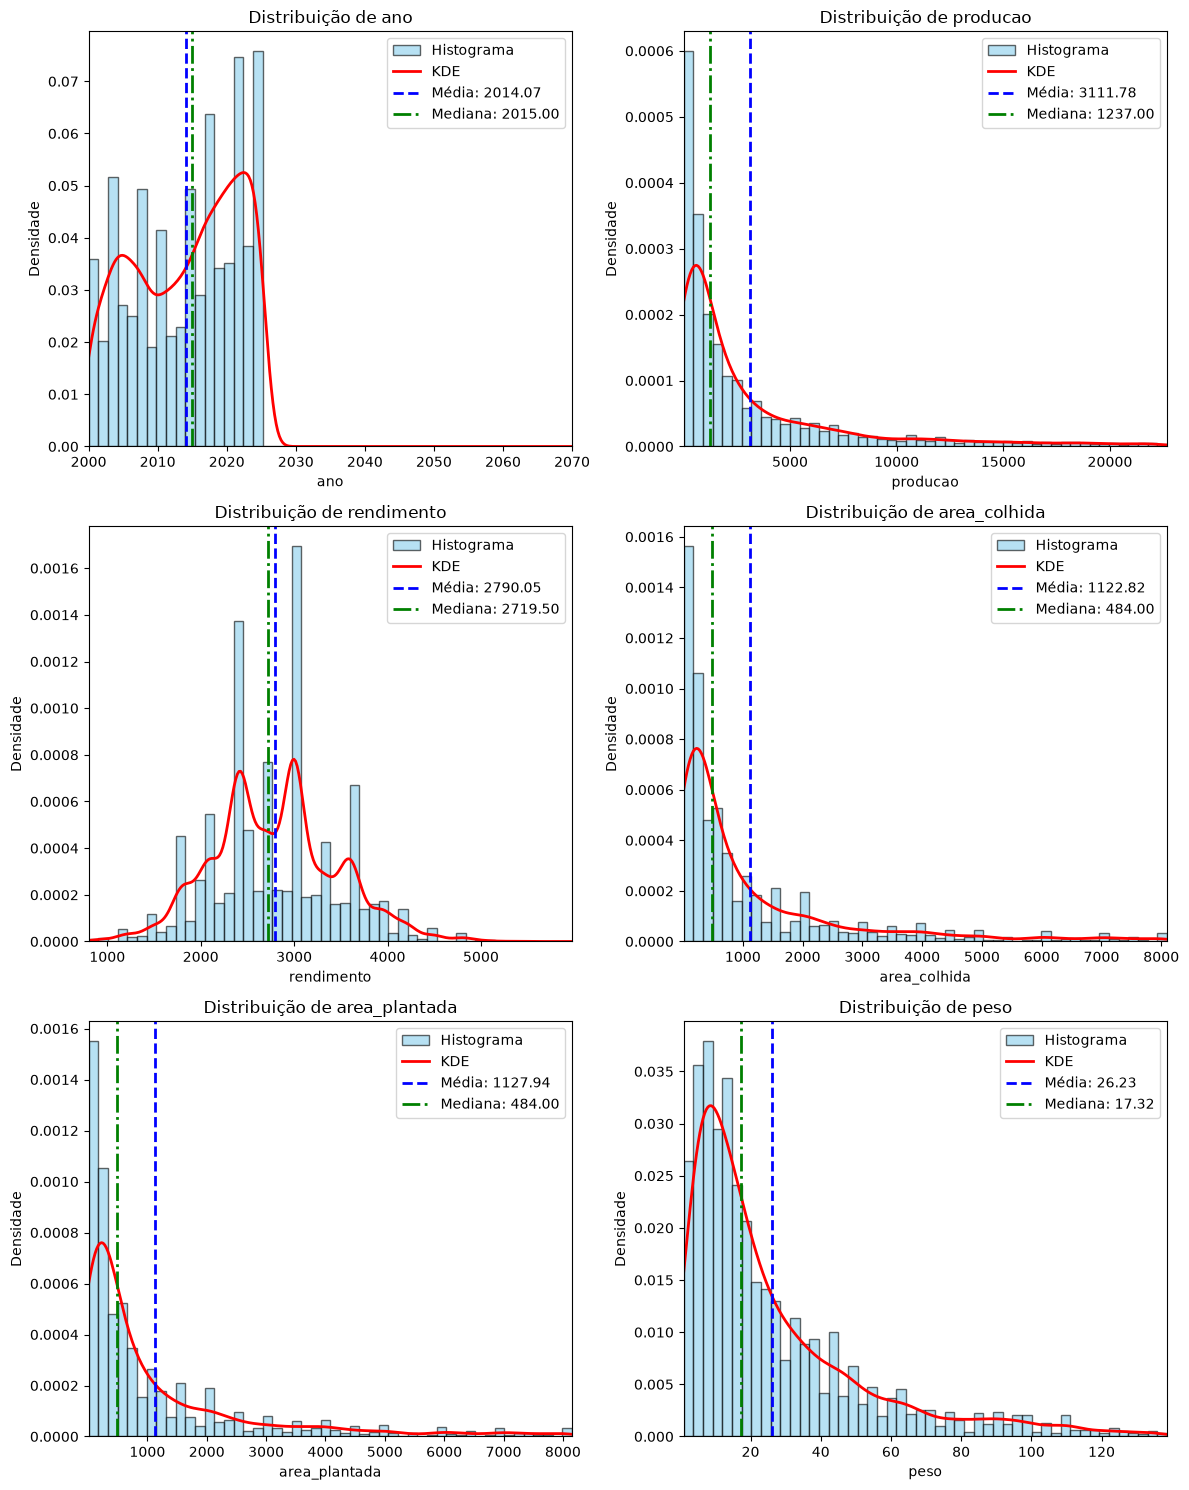

In [11]:
plot_histograms_kde(df, columns_to_plot, bins=50, ncols=2)

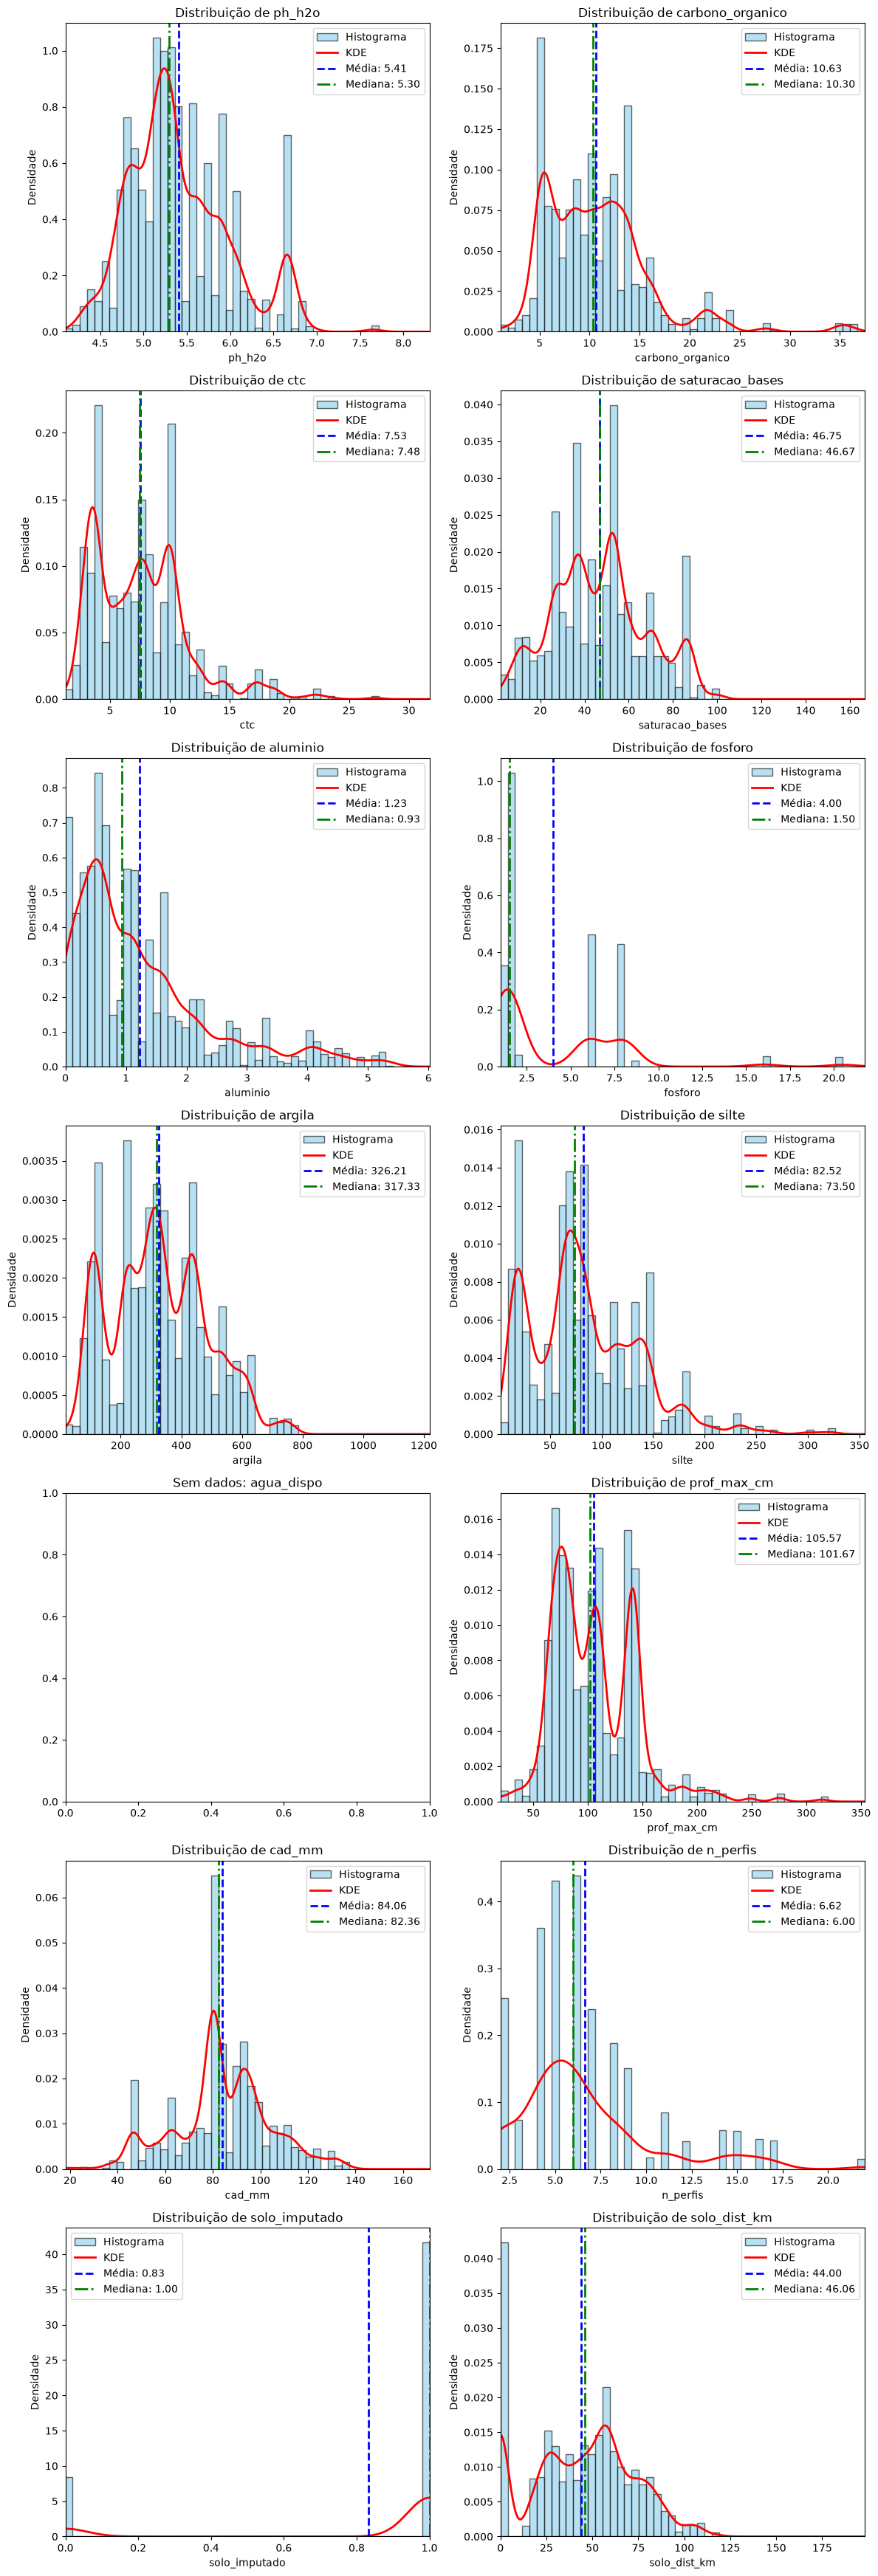

In [12]:
plot_histograms_kde(df, catalogo_variaveis.SOLO, bins=50, ncols=2)

In [ ]:
columns_to_plot_clim = [f"enchimento_{i}" for i in catalogo_variaveis.CLIMA_INDICADORES]

c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\numpy\lib\_histograms_impl.py:897: RuntimeWarning: divide by zero encountered in divide
  return n / db / n.sum(), bin_edges
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\numpy\lib\_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\matplotlib\transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
C:\Users\Samsung\AppData\Local\Temp\ipykernel_33004\1260221738.py:58: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(x_min, limite_superior)
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\matplotlib\transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  r

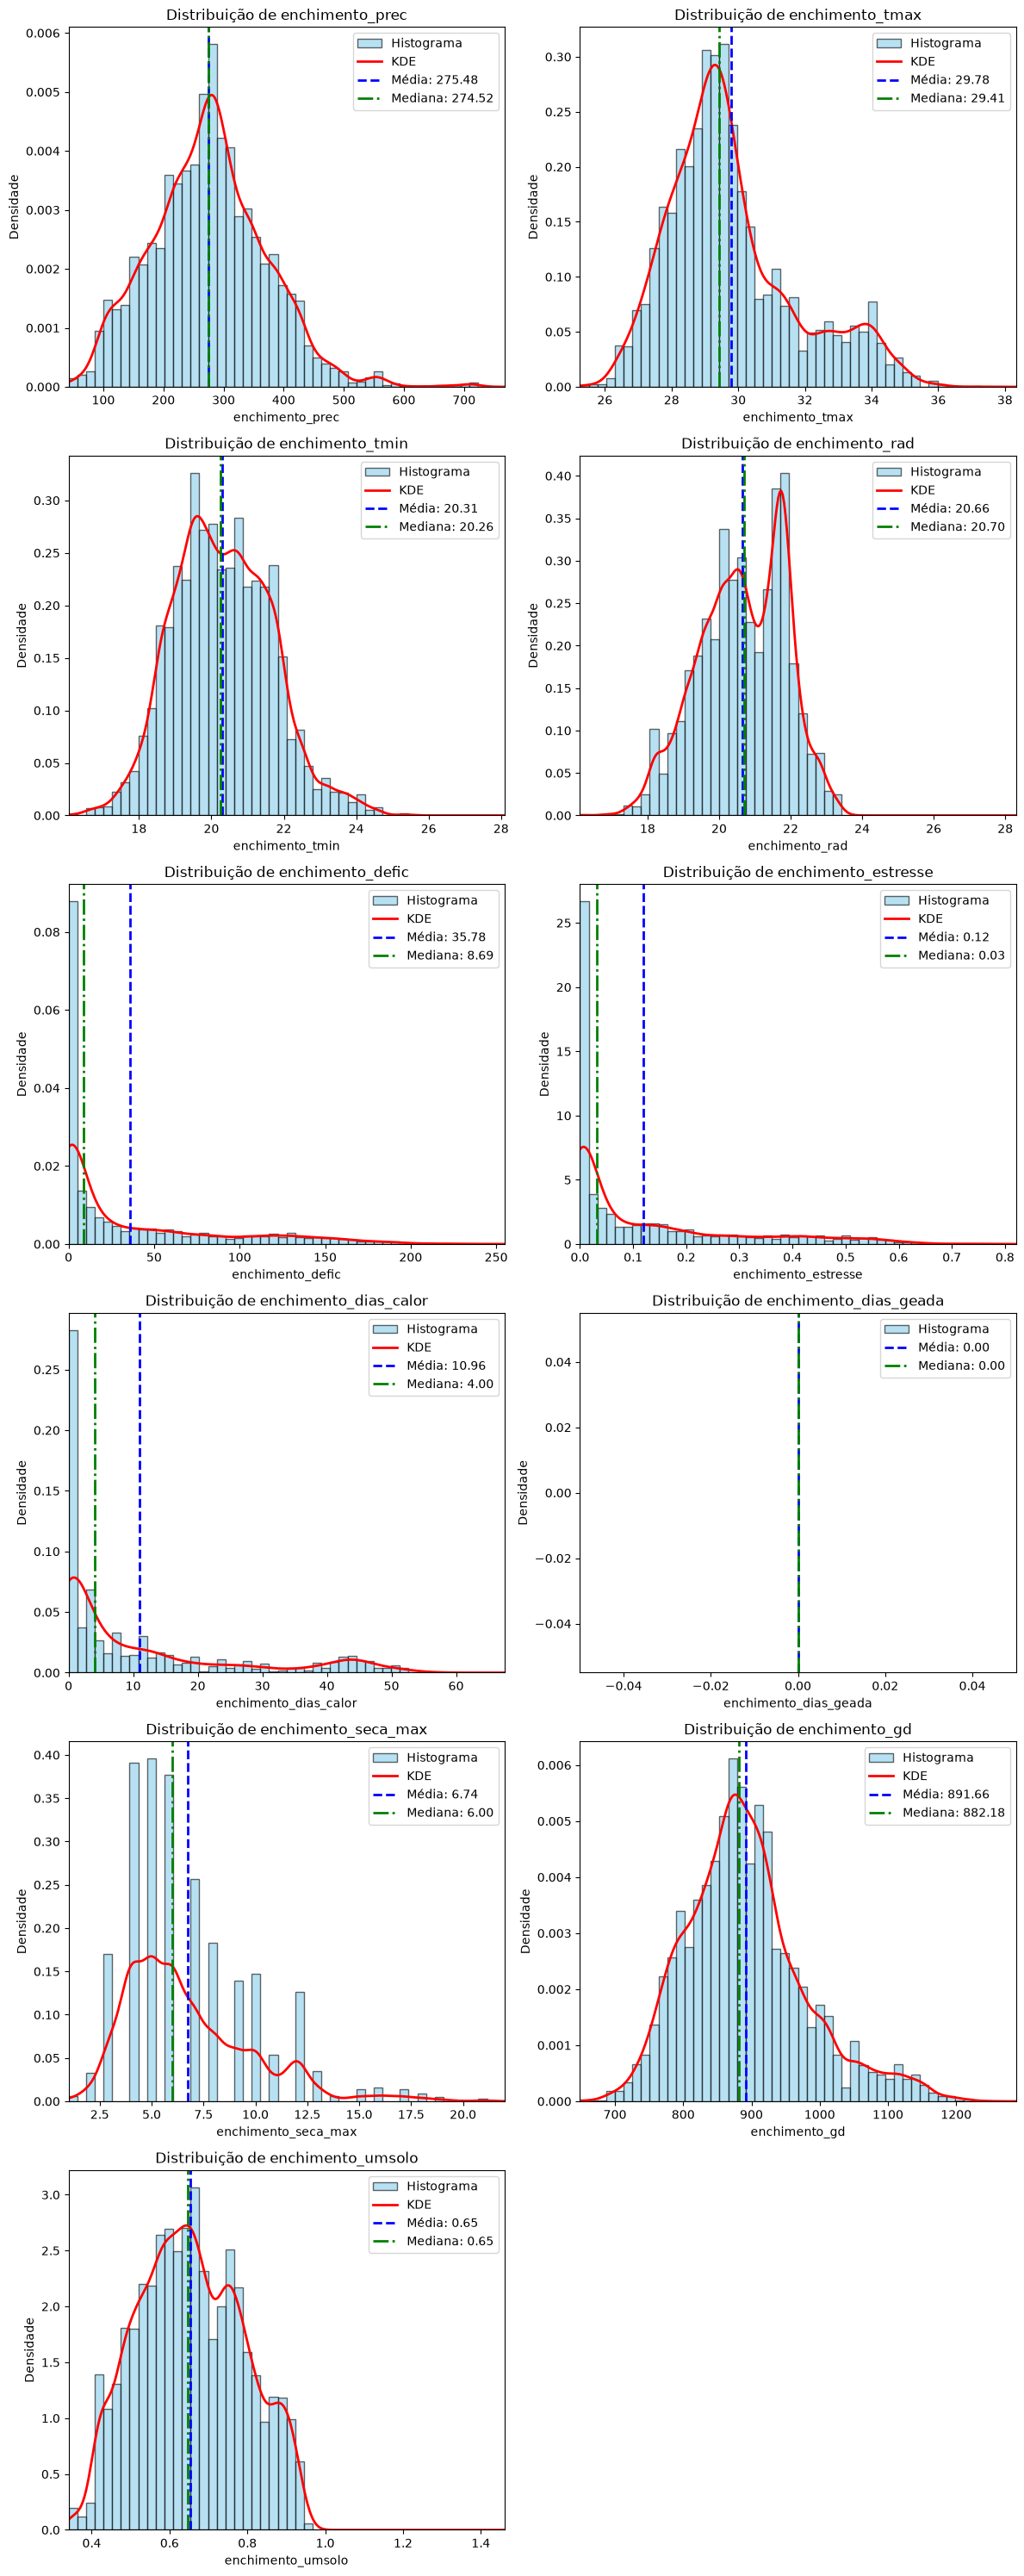

In [15]:
plot_histograms_kde(df, columns_to_plot_clim, bins=50, ncols=2)

In [ ]:
def plot_boxplots(df, columns, ncols=2, showfliers=True):
    nrows = math.ceil(len(columns) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False
    )
    axes = axes.flatten()

    for ax, col in zip(axes, columns):
        data = df[col].dropna()

        if data.empty:
            ax.set_title(f"Sem dados: {col}")
            continue

        ax.boxplot(
            data,
            vert=True,
            patch_artist=True,
            showfliers=showfliers,
            boxprops=dict(facecolor="skyblue", edgecolor="black"),
            medianprops=dict(color="red", linewidth=2),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black"),
            flierprops=dict(
                marker="o",
                markerfacecolor="orange",
                markeredgecolor="black",
                markersize=4,
                alpha=0.6,
            ),
        )

        ax.set_title(f"Boxplot de {col}")
        ax.set_ylabel(col)
        ax.set_xticks([])

    for ax in axes[len(columns) :]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

C:\Users\Samsung\AppData\Local\Temp\ipykernel_33004\1452279604.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\ipykernel_33004\1452279604.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\ipykernel_33004\1452279604.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\ipykernel_33004\1452279604.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\

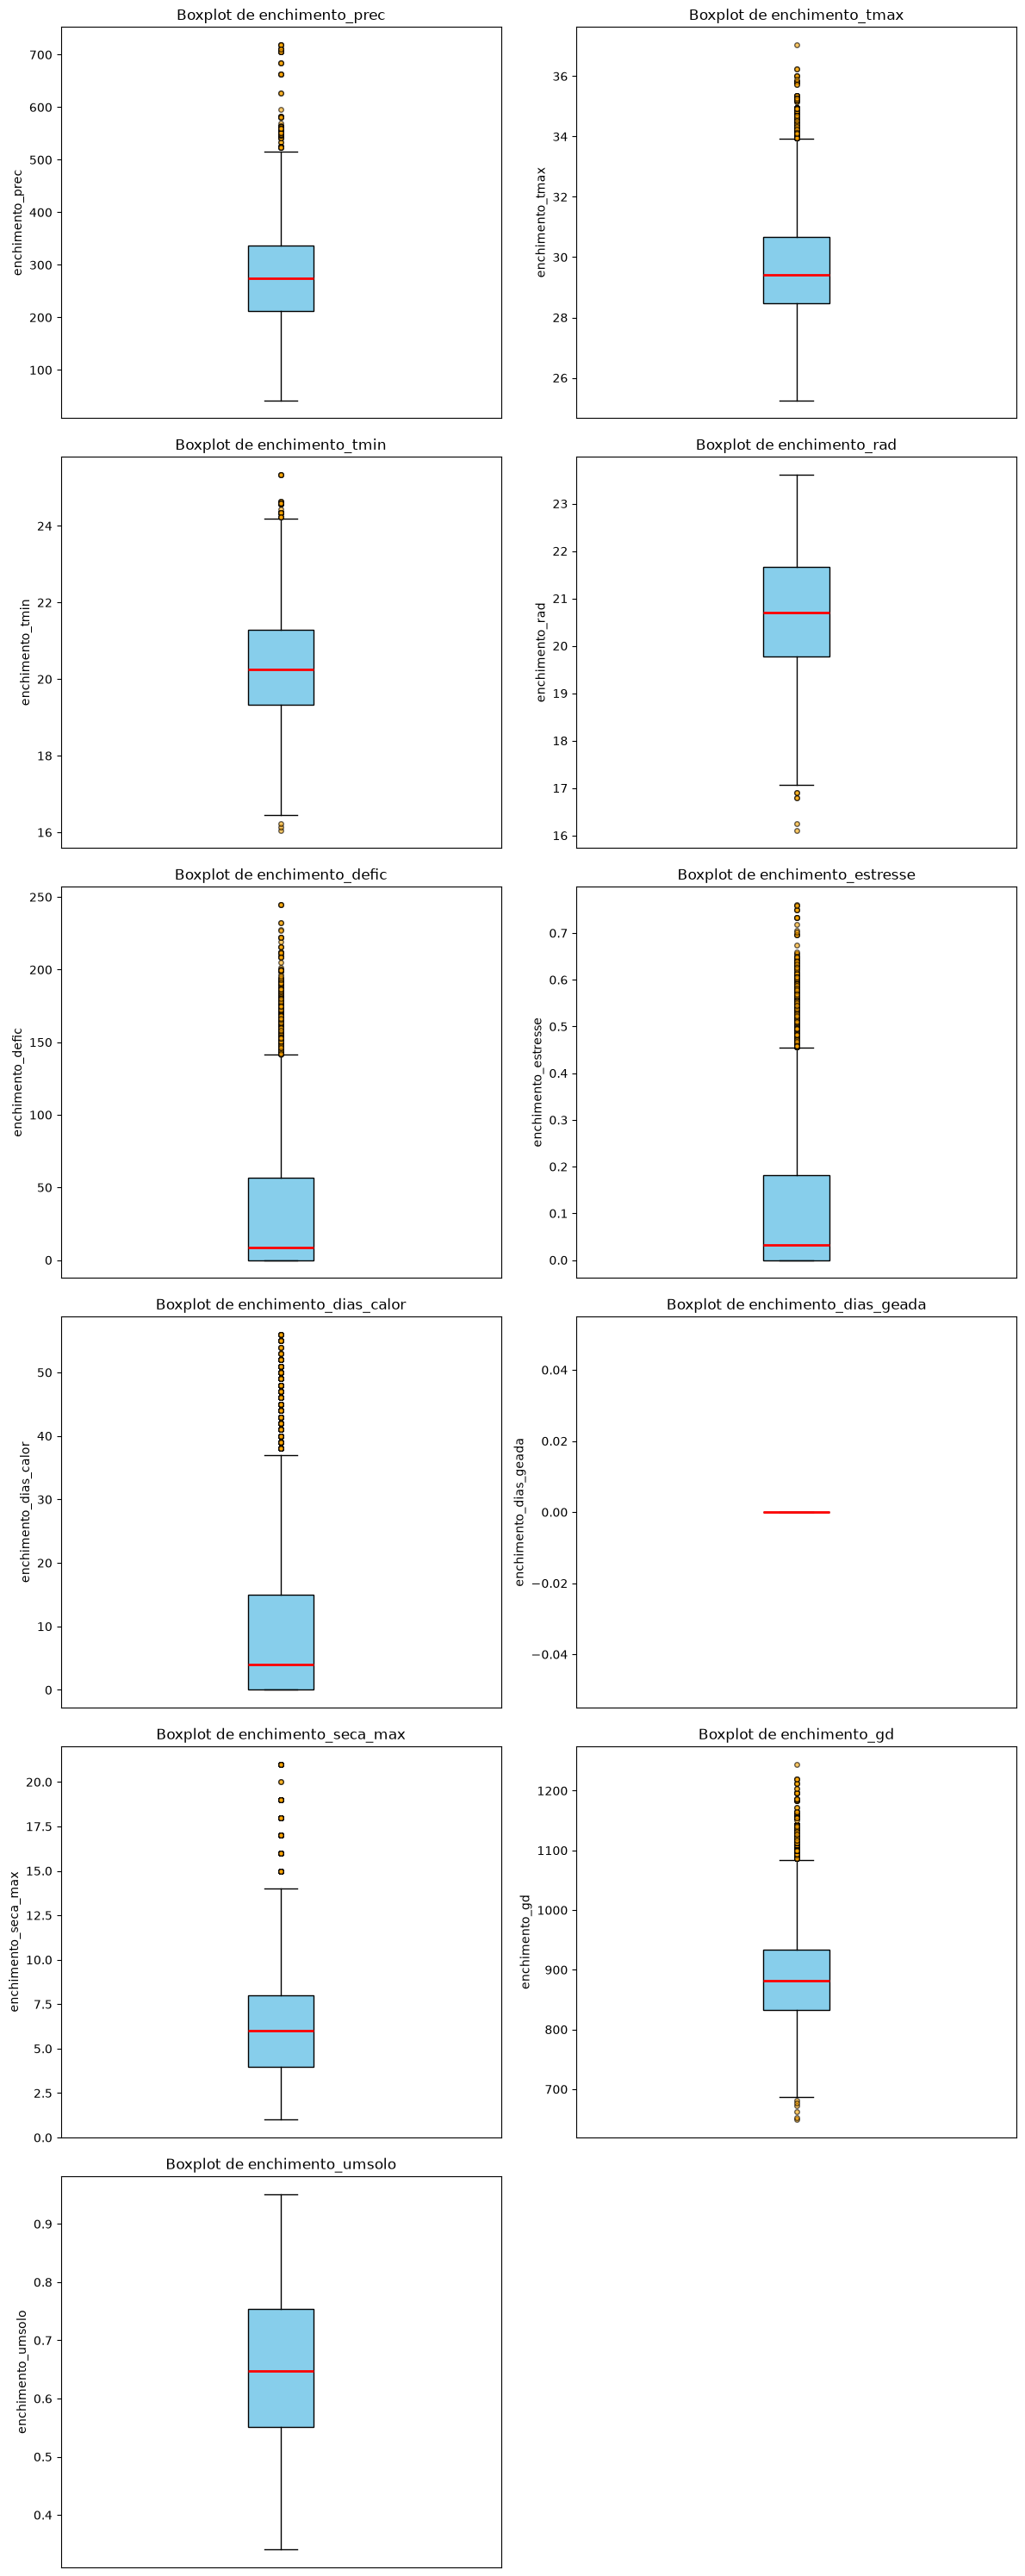

In [26]:
plot_boxplots(df, columns_to_plot_clim, ncols=2)

In [ ]:
# Dropando colunas com menos de 80% de preenchimento
df_eda = df.copy()
df_eda.dropna(axis=1, thresh=int(0.8 * len(df_eda)), inplace=True)

In [ ]:
df[]